# XGBoost Machine Learning Forecasting

## 1. Import Libraries and Load Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False
})

print("Libraries imported successfully.")

Libraries imported successfully.


### 1.1 Load the Training and Test Datasets

In [3]:
DATA_DIR = Path("../dataset/forecasting")

train = pd.read_csv(
    DATA_DIR / "train_daily.csv",
    index_col="Date",
    parse_dates=True
)

test = pd.read_csv(
    DATA_DIR / "test_daily.csv",
    index_col="Date",
    parse_dates=True
)

train = train.sort_index()
test = test.sort_index()

print("Datasets loaded successfully!")
print("Training dataset shape:", train.shape)
print("Test dataset shape:", test.shape)

print("\nTraining columns:")
print(train.columns.tolist())

print("\nTest columns:")
print(test.columns.tolist())

Datasets loaded successfully!
Training dataset shape: (900, 8)
Test dataset shape: (42, 8)

Training columns:
['Sales', 'Customers', 'OpenStores', 'StoresReporting', 'Promo', 'SchoolHoliday', 'StateHoliday', 'DayOfWeek']

Test columns:
['Sales', 'Customers', 'OpenStores', 'StoresReporting', 'Promo', 'SchoolHoliday', 'StateHoliday', 'DayOfWeek']


## 2. Data Inspection and Validation

In [4]:
print("TRAINING DATA")
print("=" * 50)
print("Date range:", train.index.min(), "to", train.index.max())
print("Number of days:", len(train))
print("Missing values:")
display(train.isnull().sum())

print("\nTEST DATA")
print("=" * 50)
print("Date range:", test.index.min(), "to", test.index.max())
print("Number of days:", len(test))
print("Missing values:")
display(test.isnull().sum())

print("\nTraining dates are continuous:",
      len(train.index) == len(pd.date_range(
          start=train.index.min(),
          end=train.index.max(),
          freq="D"
      )))

print("Test dates are continuous:",
      len(test.index) == len(pd.date_range(
          start=test.index.min(),
          end=test.index.max(),
          freq="D"
      )))

TRAINING DATA
Date range: 2013-01-01 00:00:00 to 2015-06-19 00:00:00
Number of days: 900
Missing values:


Sales              0
Customers          0
OpenStores         0
StoresReporting    0
Promo              0
SchoolHoliday      0
StateHoliday       0
DayOfWeek          0
dtype: int64


TEST DATA
Date range: 2015-06-20 00:00:00 to 2015-07-31 00:00:00
Number of days: 42
Missing values:


Sales              0
Customers          0
OpenStores         0
StoresReporting    0
Promo              0
SchoolHoliday      0
StateHoliday       0
DayOfWeek          0
dtype: int64


Training dates are continuous: True
Test dates are continuous: True


## 3. Feature Engineering

We create features that help the XGBoost model learn patterns
in daily sales.

These features include:
- Calendar features: year, month, day, and day of the week.
- Promotion and holiday information.
- Historical sales lags: sales from previous days.
- Rolling averages: average sales over previous days.

We will not use Customers, OpenStores, or StoresReporting
as input features because their future values may not be
known when forecasting.

In [5]:
def create_features(data):
    df = data.copy()

    # Calendar features
    df["Year"] = df.index.year
    df["Month"] = df.index.month
    df["Day"] = df.index.day
    df["DayOfYear"] = df.index.dayofyear
    df["WeekOfYear"] = df.index.isocalendar().week.astype(int)
    df["IsWeekend"] = (df.index.dayofweek >= 5).astype(int)

    # Historical sales features
    for lag in [1, 7, 14, 28]:
        df[f"Sales_lag_{lag}"] = df["Sales"].shift(lag)

    # Rolling averages using previous days only
    df["Sales_roll_mean_7"] = (
        df["Sales"].shift(1).rolling(window=7).mean()
    )

    df["Sales_roll_mean_14"] = (
        df["Sales"].shift(1).rolling(window=14).mean()
    )

    return df


# Create features for the training data
train_features = create_features(train)

print("Feature engineering completed!")
print("Original training shape:", train.shape)
print("Training data with features:", train_features.shape)

display(train_features.head(10))

Feature engineering completed!
Original training shape: (900, 8)
Training data with features: (900, 20)


,Sales,Customers,OpenStores,StoresReporting,Promo,SchoolHoliday,StateHoliday,DayOfWeek,Year,Month,Day,DayOfYear,WeekOfYear,IsWeekend,Sales_lag_1,Sales_lag_7,Sales_lag_14,Sales_lag_28,Sales_roll_mean_7,Sales_roll_mean_14
Date,,,,,,,,,,,,,,,,,,,,
2013-01-01,97235,19491,17,1114,0,1.000000,1.00000,2,2013,1,1,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN
2013-01-02,6949829,834075,1111,1115,0,1.000000,0.00000,3,2013,1,2,2,1,0,97235.0,NaN,NaN,NaN,NaN,NaN
2013-01-03,6347820,761040,1109,1115,0,0.932735,0.00000,4,2013,1,3,3,1,0,6949829.0,NaN,NaN,NaN,NaN,NaN
2013-01-04,6638954,782137,1108,1115,0,0.932735,0.00000,5,2013,1,4,4,1,0,6347820.0,NaN,NaN,NaN,NaN,NaN
2013-01-05,5951593,687472,1107,1115,0,0.100448,0.00000,6,2013,1,5,5,1,1,6638954.0,NaN,NaN,NaN,NaN,NaN
2013-01-06,143904,26387,19,1115,0,0.100448,0.27713,7,2013,1,6,6,1,1,5951593.0,NaN,NaN,NaN,NaN,NaN
2013-01-07,10826848,1058495,1106,1115,1,0.100448,0.00000,1,2013,1,7,7,2,0,143904.0,NaN,NaN,NaN,NaN,NaN
2013-01-08,8749437,904564,1105,1115,1,0.100448,0.00000,2,2013,1,8,8,2,0,10826848.0,97235.0,NaN,NaN,5.279455e+06,NaN
2013-01-09,7746603,816709,1105,1115,1,0.100448,0.00000,3,2013,1,9,9,2,0,8749437.0,6949829.0,NaN,NaN,6.515484e+06,NaN


### 3.1 Select Features and Target

The target variable is Sales.

We use calendar information, promotions, holidays,
historical sales lags, and rolling averages as input features.

We remove rows with missing lag values because the model
cannot train on incomplete historical features.

In [6]:
# Select the input features
feature_cols = [
    "Year",
    "Month",
    "Day",
    "DayOfYear",
    "WeekOfYear",
    "IsWeekend",
    "DayOfWeek",
    "Promo",
    "SchoolHoliday",
    "StateHoliday",
    "Sales_lag_1",
    "Sales_lag_7",
    "Sales_lag_14",
    "Sales_lag_28",
    "Sales_roll_mean_7",
    "Sales_roll_mean_14"
]

# Remove rows with missing feature values
model_data = train_features.dropna(
    subset=feature_cols + ["Sales"]
).copy()

# Separate inputs (X) from the target (y)
X_train = model_data[feature_cols]
y_train = model_data["Sales"]

print("Number of input features:", len(feature_cols))
print("Training samples after removing missing values:", len(X_train))
print("Input data shape:", X_train.shape)
print("Target data shape:", y_train.shape)

print("\nMissing values in input features:")
print(X_train.isnull().sum().sum())

print("\nTarget variable:")
print(y_train.name)

Number of input features: 16
Training samples after removing missing values: 872
Input data shape: (872, 16)
Target data shape: (872,)

Missing values in input features:
0

Target variable:
Sales


## 4. XGBoost Model and Hyperparameter Tuning

We use XGBoost Regression to predict daily sales.
Randomized Search with time-series cross-validation
will help us find suitable model hyperparameters.

In [7]:
%pip install xgboost scikit-learn

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 2.3 MB/s eta 0:00:22
   - -------------------------------------- 1.3/48.9 MB 2.3 MB/s eta 0:00:21
   - -------------------------------------- 2.1/48.9 MB 2.6 MB/s eta 0:00:18
   -- ------------------------------------- 2.6/48.9 MB 2.7 MB/s eta 0:00:18
   -- ------------------------------------- 3.4/48.9 MB 2.8 MB/s eta 0:00:17
   --- ------------------------------------ 4.2/48.9 MB 2.9 MB/s eta 0:00:16
   --- ------------------------------------ 4.7/48.9 MB 2.8 MB/s eta 0:00:16
   ---- ----------------------------------- 5.5/48.9 MB 2.9 MB/s eta 0:00:15
   ---- ----------------------------------- 6.0/48.9 MB 2.9 MB/s eta 0:00:15
   ----- ---------------------------------- 6.8/48.9 MB 3.0 MB/s eta 0:00:15
   ------ --------------------------------- 7.6/48.9 MB 3.0 MB/s eta 0:00:14
   ------ ---


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
# Check the required libraries

try:
    import xgboost
    print("XGBoost version:", xgboost.__version__)
except ImportError:
    print("XGBoost is not installed.")

try:
    import sklearn
    print("Scikit-learn version:", sklearn.__version__)
except ImportError:
    print("Scikit-learn is not installed.")

XGBoost version: 3.4.1
Scikit-learn version: 1.9.1


### 4.1 Hyperparameter Tuning with Time-Series Cross-Validation

We use RandomizedSearchCV with TimeSeriesSplit to evaluate
different XGBoost configurations while preserving the
chronological order of the training data.

The tuning score is Root Mean Squared Error (RMSE).

In [9]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

# Define the XGBoost model
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

# Define hyperparameter options
param_distributions = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [2, 3, 4, 5],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "min_child_weight": [1, 3, 5]
}

# Preserve time order during validation
time_series_cv = TimeSeriesSplit(n_splits=3)

# Search for good hyperparameters
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="neg_root_mean_squared_error",
    cv=time_series_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

# Save the best model
best_model = random_search.best_estimator_

print("\nBest hyperparameters:")
print(random_search.best_params_)

print("\nBest cross-validation RMSE:")
print(round(-random_search.best_score_, 2))

Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best hyperparameters:
{'subsample': 0.8, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 1.0}

Best cross-validation RMSE:
847664.56


### 4.2 Generate Recursive Forecasts

We forecast the test period one day at a time.

For each day, the model uses known calendar information
and historical sales. After predicting a day, we add that
prediction to the sales history for forecasting the next day.

This prevents future actual sales from leaking into the forecast.

In [10]:
# Start with actual sales from the training period
sales_history = train["Sales"].copy()

predictions = []

for date, known_row in test.iterrows():

    # Build features using only sales available before this date
    history = sales_history.loc[sales_history.index < date]

    features = {
        "Year": date.year,
        "Month": date.month,
        "Day": date.day,
        "DayOfYear": date.dayofyear,
        "WeekOfYear": int(date.isocalendar().week),
        "IsWeekend": int(date.dayofweek >= 5),
        "DayOfWeek": known_row["DayOfWeek"],
        "Promo": known_row["Promo"],
        "SchoolHoliday": known_row["SchoolHoliday"],
        "StateHoliday": known_row["StateHoliday"],
        "Sales_lag_1": history.iloc[-1],
        "Sales_lag_7": history.iloc[-7],
        "Sales_lag_14": history.iloc[-14],
        "Sales_lag_28": history.iloc[-28],
        "Sales_roll_mean_7": history.iloc[-7:].mean(),
        "Sales_roll_mean_14": history.iloc[-14:].mean()
    }

    # Arrange features in the same order used for training
    X_next = pd.DataFrame([features])[feature_cols]

    # Predict sales for this date
    predicted_sales = best_model.predict(X_next)[0]
    predictions.append(predicted_sales)

    # Add the prediction, not actual test sales, to history
    sales_history.loc[date] = predicted_sales

# Store forecasts alongside the test dates
forecast = pd.Series(
    predictions,
    index=test.index,
    name="XGBoost_Prediction"
)

print("Forecasting completed!")
print("Number of forecast days:", len(forecast))
print("\nFirst 10 predictions:")
display(forecast.head(10).to_frame())

Forecasting completed!
Number of forecast days: 42

First 10 predictions:


,XGBoost_Prediction
Date,
2015-06-20,6.438125e+06
2015-06-21,2.163979e+05
2015-06-22,6.523708e+06
2015-06-23,6.278020e+06
2015-06-24,6.193106e+06
2015-06-25,6.244880e+06
2015-06-26,6.498440e+06
2015-06-27,6.473976e+06
2015-06-28,2.770332e+05


### 4.3 Evaluate XGBoost Forecasts

We evaluate the model using:
- RMSE: penalizes large prediction errors.
- MAE: measures the average absolute error.
- MAPE: measures the average percentage error.

We also calculate MAPE for normal trading days to reduce
the effect of Sundays and other days with unusually low sales.

In [11]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Actual sales are used only for evaluation, not forecasting
y_true = test["Sales"]
y_pred = forecast

# Evaluation metrics
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)

# Avoid division by zero when calculating MAPE
nonzero_mask = y_true != 0
mape = (
    np.abs((y_true[nonzero_mask] - y_pred[nonzero_mask])
           / y_true[nonzero_mask]).mean() * 100
)

# MAPE for normal trading days
normal_days = test["OpenStores"] >= 800

normal_mape = (
    np.abs(
        (y_true[normal_days] - y_pred[normal_days])
        / y_true[normal_days]
    ).mean() * 100
)

xgb_metrics = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "MAPE (%)", "Normal-days MAPE (%)"],
    "XGBoost": [rmse, mae, mape, normal_mape]
})

display(xgb_metrics.round(2))

print("Evaluation completed!")

,Metric,XGBoost
0,RMSE,546237.24
1,MAE,408144.28
2,MAPE (%),10.04
3,Normal-days MAPE (%),5.98


Evaluation completed!


### 4.4 Actual vs. Predicted Sales

This plot compares the actual daily sales with the recursive
XGBoost forecasts throughout the 42-day test period.

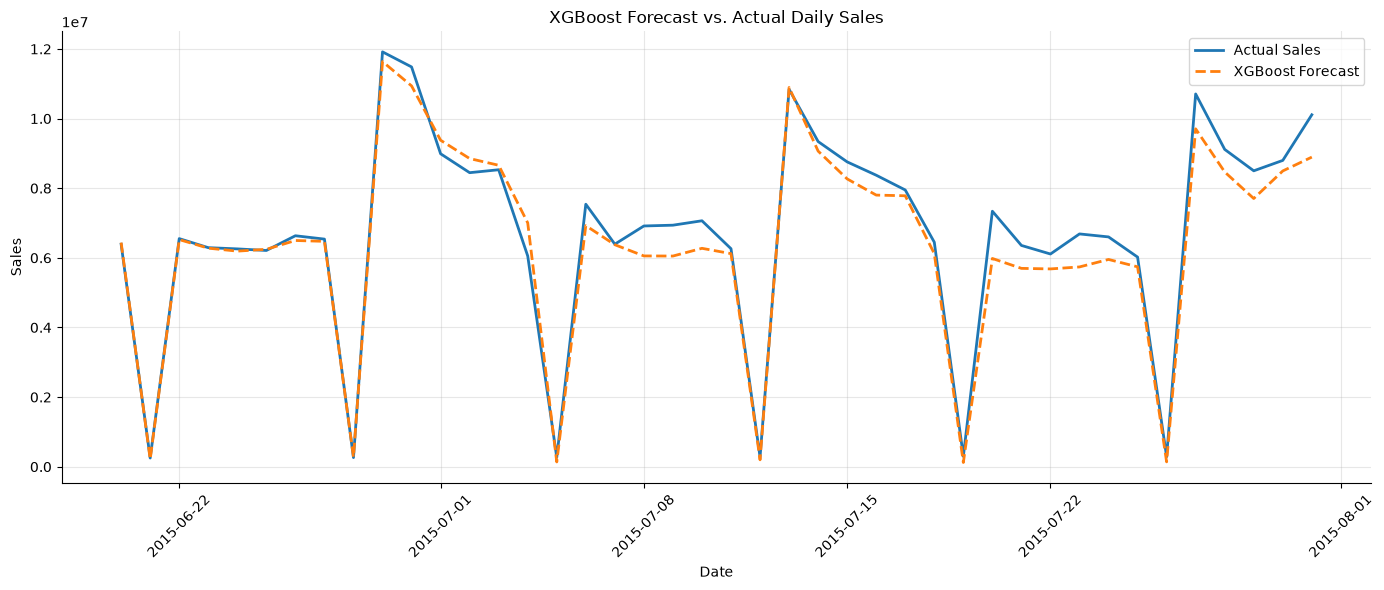

In [12]:
plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test["Sales"],
    label="Actual Sales",
    linewidth=2
)

plt.plot(
    forecast.index,
    forecast,
    label="XGBoost Forecast",
    linestyle="--",
    linewidth=2
)

plt.title("XGBoost Forecast vs. Actual Daily Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Model Comparison

We compare XGBoost with the baseline forecasting methods,
ARIMA, and SARIMA using the same 42-day test period.

Lower RMSE, MAE, and MAPE values indicate better performance.

In [13]:
# Load the existing baseline metrics
baseline_path = DATA_DIR / "baseline_metrics_holdout.csv"
baseline_metrics = pd.read_csv(baseline_path)

print("Available baseline metrics:")
display(baseline_metrics)

Available baseline metrics:


,model,RMSE,MAE,MAPE_%,MAPE_normal_%
0,Naive (last value),3512021.99,2507472.14,446.83,21.49
1,Seasonal naive (7d),1775080.15,1179019.24,17.41,19.52
2,Seasonal naive (14d),527462.31,354693.05,5.09,5.09
3,Seasonal naive (364d),1338134.67,1081606.19,14.73,15.67


### 5.1 Comparison of Forecasting Performance

We compare the machine learning model against the baseline
and statistical forecasting models using RMSE, MAE, and MAPE.

The same test period is used for all models.

In [14]:
# Start with the baseline results
comparison = baseline_metrics[
    ["model", "RMSE", "MAE", "MAPE_%", "MAPE_normal_%"]
].copy()

# Add ARIMA and SARIMA results from the previous analysis
statistical_results = pd.DataFrame([
    {
        "model": "ARIMA(1,1,1)",
        "RMSE": 3058326.28,
        "MAE": 2148282.64,
        "MAPE_%": 330.76,
        "MAPE_normal_%": 16.19
    },
    {
        "model": "SARIMA(1,1,1)(1,1,1,7)",
        "RMSE": 1339830.16,
        "MAE": 1094546.73,
        "MAPE_%": 29.03,
        "MAPE_normal_%": 16.08
    }
])

# Add XGBoost results
xgboost_results = pd.DataFrame([
    {
        "model": "XGBoost",
        "RMSE": rmse,
        "MAE": mae,
        "MAPE_%": mape,
        "MAPE_normal_%": normal_mape
    }
])

# Combine all models
comparison = pd.concat(
    [comparison, statistical_results, xgboost_results],
    ignore_index=True
)

# Sort models by RMSE (lowest is best)
comparison = comparison.sort_values("RMSE").reset_index(drop=True)

print("Forecasting Model Comparison")
display(comparison.round(2))

Forecasting Model Comparison


,model,RMSE,MAE,MAPE_%,MAPE_normal_%
0,Seasonal naive (14d),527462.31,354693.05,5.09,5.09
1,XGBoost,546237.24,408144.28,10.04,5.98
2,Seasonal naive (364d),1338134.67,1081606.19,14.73,15.67
3,"SARIMA(1,1,1)(1,1,1,7)",1339830.16,1094546.73,29.03,16.08
4,Seasonal naive (7d),1775080.15,1179019.24,17.41,19.52
5,"ARIMA(1,1,1)",3058326.28,2148282.64,330.76,16.19
6,Naive (last value),3512021.99,2507472.14,446.83,21.49


6. Results and Conclusions

Model Performance

The XGBoost regression model was trained using calendar features, promotion and holiday information, historical sales lags, and rolling averages. Hyperparameters were tuned using RandomizedSearchCV with time-series cross-validation.

The tuned model generated recursive forecasts for the 42-day test period, achieving:

* RMSE: 546,237.24
* MAE: 408,144.28
* MAPE: 10.04%
* Normal-days MAPE: 5.98%

Comparison with Other Models

Seasonal Naive (14-day) achieved the best overall results, with an RMSE of 527,462.31 and an MAE of 354,693.05. XGBoost ranked second based on RMSE and outperformed the ARIMA and SARIMA models on both RMSE and MAE.

Conclusion

Although XGBoost did not outperform the best baseline, it demonstrated competitive forecasting performance while incorporating multiple calendar, promotion, holiday, and historical-sales features. Seasonal Naive (14-day) remains the strongest model among those evaluated on this test period.

Further improvements could include additional lag features, alternative rolling windows, more extensive hyperparameter tuning, and evaluation across multiple time-based validation periods.

### 6.1 Export Forecasts and Evaluation Results

Save the XGBoost predictions and model comparison table
for reporting and further analysis.

In [15]:
# Save XGBoost predictions alongside actual sales
forecast_results = pd.DataFrame({
    "Actual_Sales": test["Sales"],
    "XGBoost_Prediction": forecast
})

forecast_results.to_csv(
    DATA_DIR / "xgboost_forecasts.csv",
    index_label="Date"
)

# Save the comparison of all evaluated models
comparison.to_csv(
    DATA_DIR / "forecast_model_comparison.csv",
    index=False
)

print("Results saved successfully:")
print(DATA_DIR / "xgboost_forecasts.csv")
print(DATA_DIR / "forecast_model_comparison.csv")

Results saved successfully:
..\dataset\forecasting\xgboost_forecasts.csv
..\dataset\forecasting\forecast_model_comparison.csv


### 6.2 Save the Tuned XGBoost Model

Save the best tuned model so it can be loaded and reused later.

In [16]:
import joblib

model_path = DATA_DIR / "xgboost_best_model.joblib"

joblib.dump(best_model, model_path)

print("Tuned model saved successfully!")
print(model_path)

Tuned model saved successfully!
..\dataset\forecasting\xgboost_best_model.joblib
